## To Do:

- x make a plotting function
    - x make option to add coasts
    - x make option to add country borders
- o are there other features that might be usefull and easy to implement?
    - o mountains
    - o forests
    - ...
- o adapt tutorial (maybe even write new one)

In [53]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np
from matplotlib.colors import ListedColormap

def plot(
    ponds,
    verbose: bool = False,
    figsize: tuple = (16, 8),
    coastline: bool = True,
    borders: bool = True,
    show_cells: bool = False,
):
    """Plot the PONDS data on a world map using lat/lon as axis ticks."""

    # Extract cluster masks
    cluster_masks = []
    if verbose: print("Extracting cluster masks...")
    cluster_key = ponds.data.attrs["cluster_key"]
    for name, da in ponds.data.data_vars.items():
        if name.startswith(cluster_key):
            if verbose: print(f"Found cluster variable: {name}")
            cluster_masks.append(da)
    if verbose: print(f"Found {len(cluster_masks)} cluster variables.")

    # Specify Colors
    cland = "#fff3e0"
    cocean = "#e0f7fa"
    cblobs = [
        "#d36060",  # soft red
        "#f0a830",  # warm orange
        "#f6d55c",  # pastel yellow
        "#7bc043",  # fresh green
        "#69d2e7",  # sky blue
        "#6384b3",  # dusty blue
        "#f17cb0",  # pink rose
        "#c894d5",  # light purple
        "#ff9671",  # coral
        "#52b788",  # soft teal
        "#6c5ce7",  # indigo
    ]

    # Set up map with Cartopy
    fig, ax = plt.subplots(
        figsize=figsize,
        subplot_kw={'projection': ccrs.PlateCarree()}
    )

    # Add map features
    if borders:
        ax.add_feature(cfeature.BORDERS, linestyle=':')
        ax.add_feature(cfeature.LAND, facecolor=cland)
        ax.add_feature(cfeature.OCEAN, facecolor=cocean)
    if coastline:
        ax.add_feature(cfeature.COASTLINE)
        ax.add_feature(cfeature.LAND, facecolor=cland)
        ax.add_feature(cfeature.OCEAN, facecolor=cocean)
    if not show_cells:
        ax.gridlines(
            draw_labels=True,
            colors='gray',
            linestyle='-.',
        )
    else:
        ax.gridlines(draw_labels=True, color='none')


    for i, mask in enumerate(cluster_masks):
        if verbose: print(f"Plotting mask {i+1} with shape {mask.shape}")

        collapsed = mask.any(dim='time').astype(int)

        # Get lat/lon coordinates safely
        lat = collapsed.coords['lat'].values
        lon = collapsed.coords['lon'].values

        # Define image extent from lat/lon
        extent = [lon.min(), lon.max(), lat.min(), lat.max()]

        # Plot the mask on the map
        ax.imshow(
            collapsed,
            cmap=ListedColormap(['none' , cblobs[i % len(cblobs)]]),
            alpha=0.6,
            extent=extent,
            origin='lower',
            transform=ccrs.PlateCarree()
        )

         # Add contour outlines (white)
        ax.contour(
            lon, lat, collapsed.astype(int),
            levels=[0.5],
            colors=cblobs[i % len(cblobs)],
            linewidths=2,
            transform=ccrs.PlateCarree()
        )

    # Add optional grid lines based on lat/lon spacing
    if show_cells:
        if verbose: print("Drawing grid lines based on xarray resolution...")
        # Compute midpoints and deltas
        lat_edges = _get_grid_edges(lat)
        lon_edges = _get_grid_edges(lon)

        for x in lon_edges:
            ax.plot([x, x], [lat_edges[0], lat_edges[-1]],
                    color='black', linewidth=0.5, alpha=0.3,
                    transform=ccrs.PlateCarree(), zorder=10,
                    )

        for y in lat_edges:
            ax.plot([lon_edges[0], lon_edges[-1]], [y, y],
                    color='black', linewidth=0.5, alpha=0.3,
                    transform=ccrs.PlateCarree(), zorder=10,
                    )

    ax.set_title("Cluster Masks")
    plt.show()

def _get_grid_edges(coords: np.ndarray):
    """Helper to calculate grid edges from 1D coordinate centers."""

    # Calculate edge positions
    step = (coords[-1] - coords[0]) / (len(coords))
    edges = np.arange(coords[0], coords[-1]+step, step)
    return edges

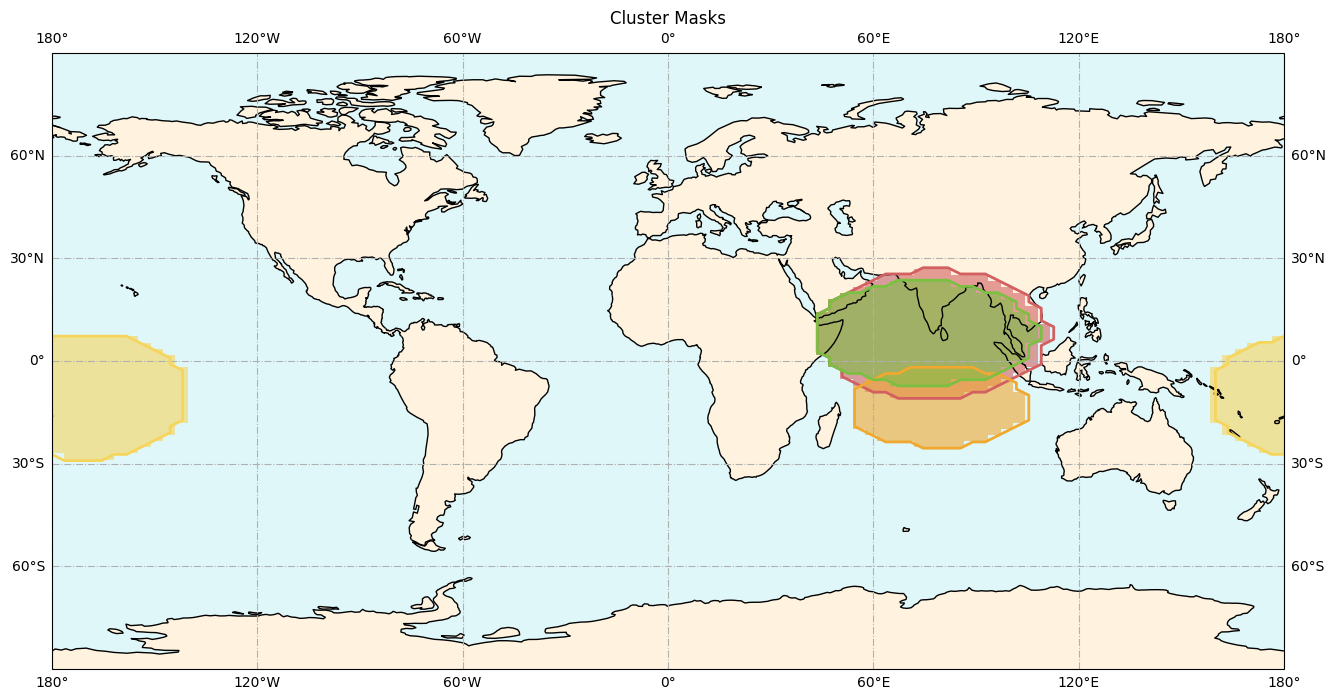

In [1]:
from ponds import PONDS, GAUSS, SIGMOID, WhiteNoise

pd = PONDS(
    lat_size=100,
    lon_size=100,
    time_size=100,)

pd.add_perturbation(
    perturbation_method=WhiteNoise(),
)


for i in range(4):
    pd.add_shift(
        shift_method=SIGMOID(),
        shape_method=GAUSS(random_seed=i),
    )

pd.worldmap(
    #coastline=False,
    borders=False,
    #show_cells=True,
    )

In [11]:
lon_size = 4
np.linspace(-180, 180, lon_size)

array([-180.,  -60.,   60.,  180.])